In [1]:
import numpy as np
import pandas as pd
import matplotlib.pylab as plt
import warnings
warnings.filterwarnings('ignore')

import seaborn as sns

About Dataset:

Machine Predictive Maintenance Classification Dataset
Since real predictive maintenance datasets are generally difficult to obtain and in particular difficult to publish, we present and provide a synthetic dataset that reflects real predictive maintenance encountered in the industry to the best of our knowledge.

The dataset consists of 10 000 data points stored as rows with 14 features in columns

    - UID: unique identifier ranging from 1 to 10000
    - productID: consisting of a letter L, M, or H for low (50% of all products), medium (30%), and high (20%) as product quality variants and a variant-specific serial number
    - air temperature [K]: generated using a random walk process later normalized to a standard deviation of 2 K around 300 K
    - process temperature [K]: generated using a random walk process normalized to a standard deviation of 1 K, added to the air temperature plus 10 K.
    - rotational speed [rpm]: calculated from powepower of 2860 W, overlaid with a normally distributed noise
    - torque [Nm]: torque values are normally distributed around 40 Nm with an Ïƒ = 10 Nm and no negative values.
    - tool wear [min]: The quality variants H/M/L add 5/3/2 minutes of tool wear to the used tool in the process. and a
    'machine failure' label that indicates, whether the machine has failed in this particular data point for any of the following failure modes are true.
    - Important : There are two Targets - Do not make the mistake of using one of them as feature, as it will lead to leakage.
    - Target : Failure or Not
    - Failure Type : Type of Failure
    
    Acknowledgements: https://archive.ics.uci.edu/ml/datasets/AI4I+2020+Predictive+Maintenance+Dataset

In [2]:
# IMport dataset

df = pd.read_csv('predictive_maintenance.csv')
df.head()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Target,Failure Type
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,No Failure
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,No Failure
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,No Failure
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,No Failure
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,No Failure


In [3]:
# shape
df.shape

(10000, 10)

In [4]:
# Info
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 10 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Target                   10000 non-null  int64  
 9   Failure Type             10000 non-null  object 
dtypes: float64(3), int64(4), object(3)
memory usage: 781.4+ KB


In [5]:
# description
df.describe()

,UDI,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Target
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,5000.50000,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900
std,2886.89568,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981
min,1.00000,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000
25%,2500.75000,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000
50%,5000.50000,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000
75%,7500.25000,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000
max,10000.00000,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000


In [6]:
# Target
df['Target'].value_counts()

Target
0    9661
1     339
Name: count, dtype: int64

In [7]:
# Target percentage
df['Target'].value_counts()*100/df['Target'].count()

Target
0    96.61
1     3.39
Name: count, dtype: float64

- We have 339 event based on that we have to make predictive maintenance model
- This is called an imbalanced dataset. In that situation, accuracy alone can be misleading. We should also evaluate Recall, Precision, and F1-score.

In [8]:
df['Failure Type'].value_counts()

Failure Type
No Failure                  9652
Heat Dissipation Failure     112
Power Failure                 95
Overstrain Failure            78
Tool Wear Failure             45
Random Failures               18
Name: count, dtype: int64

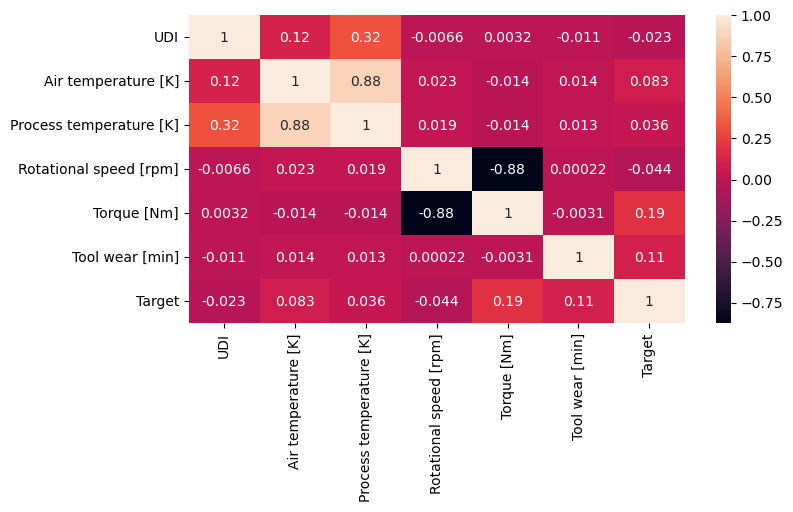

In [9]:
corr = df.corr(numeric_only=True)
plt.figure(figsize=(8,4))
sns.heatmap(corr, annot=True, )
plt.show()

<Axes: xlabel='Air temperature [K]', ylabel='Rotational speed [rpm]'>

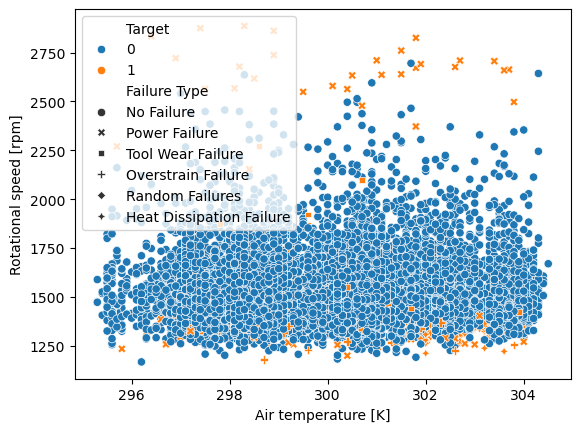

In [10]:
sns.scatterplot(data=df, x='Air temperature [K]', y='Rotational speed [rpm]',hue='Target', style='Failure Type')

<Axes: xlabel='Process temperature [K]', ylabel='Rotational speed [rpm]'>

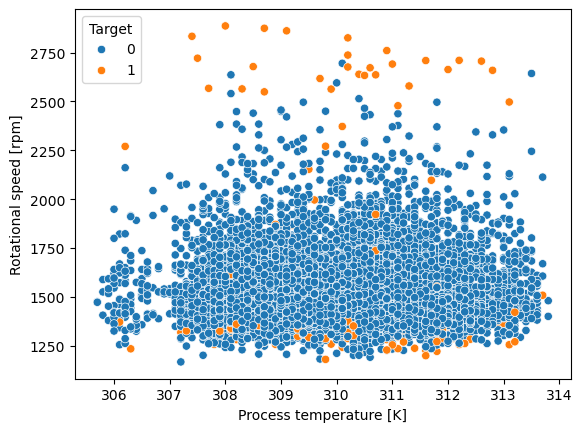

In [11]:
# Scatter Plot

sns.scatterplot(data=df, x='Process temperature [K]', y='Rotational speed [rpm]',hue='Target')

In [12]:
df.columns

Index(['UDI', 'Product ID', 'Type', 'Air temperature [K]',
       'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]',
       'Tool wear [min]', 'Target', 'Failure Type'],
      dtype='object')

<Axes: xlabel='Torque [Nm]', ylabel='Rotational speed [rpm]'>

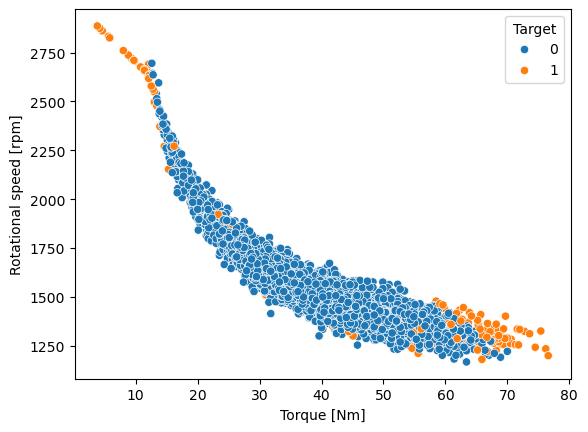

In [13]:
sns.scatterplot(data=df, x='Torque [Nm]', y='Rotational speed [rpm]',hue='Target')

<Axes: xlabel='Tool wear [min]', ylabel='Rotational speed [rpm]'>

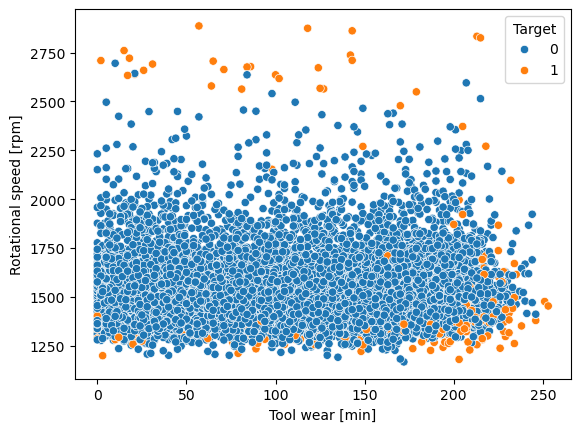

In [14]:
sns.scatterplot(data=df, x='Tool wear [min]', y='Rotational speed [rpm]',hue='Target')

<Axes: xlabel='Torque [Nm]', ylabel='Air temperature [K]'>

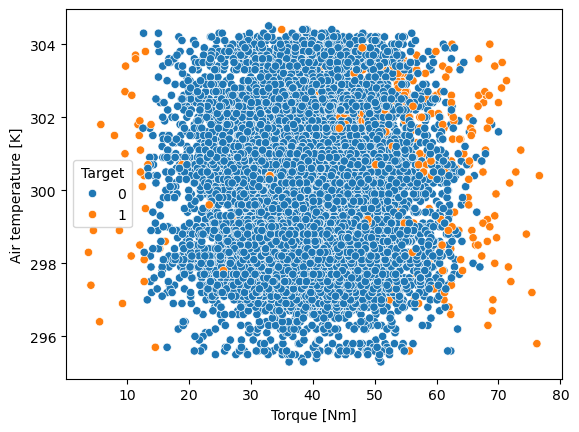

In [15]:
sns.scatterplot(data=df, x='Torque [Nm]', y='Air temperature [K]',hue='Target')

In [16]:
df.columns

Index(['UDI', 'Product ID', 'Type', 'Air temperature [K]',
       'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]',
       'Tool wear [min]', 'Target', 'Failure Type'],
      dtype='object')

<Axes: xlabel='Torque [Nm]', ylabel='Tool wear [min]'>

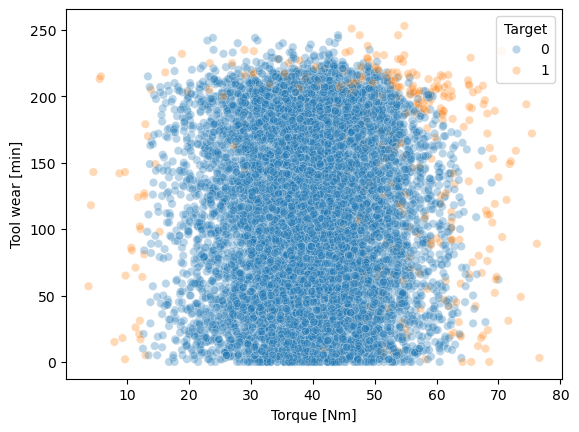

In [17]:
sns.scatterplot(data=df, x='Torque [Nm]', y='Tool wear [min]',hue='Target', alpha= 0.3)

In [18]:
variable = []

In [19]:
df.columns

Index(['UDI', 'Product ID', 'Type', 'Air temperature [K]',
       'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]',
       'Tool wear [min]', 'Target', 'Failure Type'],
      dtype='object')

In [20]:
df.head()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Target,Failure Type
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,No Failure
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,No Failure
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,No Failure
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,No Failure
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,No Failure


In [21]:
df_new = pd.get_dummies(df, columns=['Type'], drop_first=True, dtype=int)

In [22]:
df_new.head()

,UDI,Product ID,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Target,Failure Type,Type_L,Type_M
0,1,M14860,298.1,308.6,1551,42.8,0,0,No Failure,0,1
1,2,L47181,298.2,308.7,1408,46.3,3,0,No Failure,1,0
2,3,L47182,298.1,308.5,1498,49.4,5,0,No Failure,1,0
3,4,L47183,298.2,308.6,1433,39.5,7,0,No Failure,1,0
4,5,L47184,298.2,308.7,1408,40.0,9,0,No Failure,1,0


In [23]:
x = df_new[['Air temperature [K]', 'Process temperature [K]',
       'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]','Type_L', 'Type_M' ]]

y = df_new[['Target']]

In [24]:
x.head()

,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Type_L,Type_M
0,298.1,308.6,1551,42.8,0,0,1
1,298.2,308.7,1408,46.3,3,1,0
2,298.1,308.5,1498,49.4,5,1,0
3,298.2,308.6,1433,39.5,7,1,0
4,298.2,308.7,1408,40.0,9,1,0


In [25]:
y.head()

,Target
0,0
1,0
2,0
3,0
4,0


In [26]:
from sklearn.model_selection import train_test_split

In [27]:
x_train, x_test, y_train, y_test = train_test_split(x,y,test_size=0.2, random_state=42, stratify=y)

In [32]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

In [35]:
# Build LOgistic regression

from sklearn.linear_model import LogisticRegression

model = LogisticRegression(random_state= 42, max_iter=1000)

model.fit(x_train_scaled, y_train) # model trained now

LogisticRegression(max_iter=1000, random_state=42)

In [36]:
# Predict trained model on the test-scaled

y_pred = model.predict(x_test_scaled)

In [38]:
y_prob = model.predict_proba(x_test_scaled)
y_prob [:5]

array([[3.95409506e-01, 6.04590494e-01],
       [9.69402453e-01, 3.05975467e-02],
       [9.48416626e-01, 5.15833741e-02],
       [9.99694423e-01, 3.05576594e-04],
       [8.17148452e-01, 1.82851548e-01]])

In [40]:
# MOdel Evaluation

from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

print('Accuracy_Score:', accuracy_score(y_test, y_pred))

Accuracy_Score: 0.9675


In [42]:
#Confusion Matrix
confu_mat = confusion_matrix (y_test, y_pred)
confu_mat

array([[1928,    4],
       [  61,    7]], dtype=int64)

In [47]:
# Classification report

print( classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.97      1.00      0.98      1932
           1       0.64      0.10      0.18        68

    accuracy                           0.97      2000
   macro avg       0.80      0.55      0.58      2000
weighted avg       0.96      0.97      0.96      2000



-  Above logistic Regression model performing well interms of overall accuracy
-  But not performing well at detecting machine failure
- so we need to increase True Positive (TP). score 68 machines actually experienced failure. Only 7 detected by the model. 61 failures were missed.
- 

## Balanced Logistic Regression

In [49]:
model_balanced = LogisticRegression(
    class_weight='balanced',
    random_state=42,
    max_iter=1000
)

model_balanced.fit(x_train_scaled, y_train)

y_pred_balanced = model_balanced.predict(x_test_scaled)

print(confusion_matrix(y_test, y_pred_balanced))
print(classification_report(y_test, y_pred_balanced))

[[1593  339]
 [  12   56]]
              precision    recall  f1-score   support

           0       0.99      0.82      0.90      1932
           1       0.14      0.82      0.24        68

    accuracy                           0.82      2000
   macro avg       0.57      0.82      0.57      2000
weighted avg       0.96      0.82      0.88      2000



- Now Out of 68 actual failures: 56 detected, 12 missed
- But Now you can see that out of 1932 normal machines: 339 incorrectly flagged: that is **false alarm**